# Finance AI

**Finance AI Agent – Data Analysis, Preprocessing, Regression Models, Evaluation and Model Saving**

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import joblib
import os

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import warnings
warnings.filterwarnings("ignore")

## Load Finance Dataset

In [2]:
finance_df = pd.read_csv("finance_ml_df.csv")

print(finance_df.shape)
finance_df.head()

(88, 28)


,year,month,quarter,week,weekly_revenue,weekly_orders,total_qty_sold,weekly_freight_cost,avg_order_value,purchase_cost,...,profit_lag_1,profit_lag_2,profit_lag_3,orders_lag_1,orders_lag_2,rolling_revenue_4w,rolling_profit_4w,rolling_orders_4w,target_next_week_revenue,target_next_week_net_profit
0,2016,12,4,51,10.90,1,1.0,8.72,10.900000,6.795090,...,-24159.106404,-23420.558429,-29985.036484,37.0,253.0,11178.7900,-27439.599494,73.00,3374.76,-31276.562867
1,2017,1,1,1,3374.76,46,47.0,578.41,73.364348,2103.822610,...,-21406.112478,-24159.106404,-23420.558429,1.0,37.0,11163.2925,-24742.703449,73.00,12772.34,-26427.486987
2,2017,1,1,2,12772.34,78,88.0,1789.18,163.747949,7774.683546,...,-31276.562867,-21406.112478,-24159.106404,46.0,1.0,11973.2400,-25065.585045,84.25,24310.46,-26868.688443
3,2017,1,1,3,24310.46,195,239.0,4007.78,124.669026,17744.847082,...,-26427.486987,-31276.562867,-21406.112478,78.0,46.0,4962.6425,-25817.317184,40.50,57723.45,-19588.809660
4,2017,1,1,4,57723.45,350,419.0,7801.41,164.924143,39838.834849,...,-26868.688443,-26427.486987,-31276.562867,195.0,78.0,10117.1150,-26494.712694,80.00,71578.35,-17353.866649


## Dataset Information

In [3]:
finance_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 88 entries, 0 to 87
Data columns (total 28 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   year                         88 non-null     int64  
 1   month                        88 non-null     int64  
 2   quarter                      88 non-null     int64  
 3   week                         88 non-null     int64  
 4   weekly_revenue               88 non-null     float64
 5   weekly_orders                88 non-null     int64  
 6   total_qty_sold               88 non-null     float64
 7   weekly_freight_cost          88 non-null     float64
 8   avg_order_value              88 non-null     float64
 9   purchase_cost                88 non-null     float64
 10  marketing_cost               88 non-null     float64
 11  salary_cost                  88 non-null     float64
 12  rent_cost                    88 non-null     float64
 13  gross_profit          

## Check Missing Values

In [4]:
finance_df.isnull().sum()

year                           0
month                          0
quarter                        0
week                           0
weekly_revenue                 0
weekly_orders                  0
total_qty_sold                 0
weekly_freight_cost            0
avg_order_value                0
purchase_cost                  0
marketing_cost                 0
salary_cost                    0
rent_cost                      0
gross_profit                   0
net_profit                     0
revenue_lag_1                  0
revenue_lag_2                  0
revenue_lag_3                  0
profit_lag_1                   0
profit_lag_2                   0
profit_lag_3                   0
orders_lag_1                   0
orders_lag_2                   0
rolling_revenue_4w             0
rolling_profit_4w              0
rolling_orders_4w              0
target_next_week_revenue       0
target_next_week_net_profit    0
dtype: int64

## Check Duplicate Rows

In [5]:
finance_df.duplicated().sum()

np.int64(0)

In [6]:
finance_df = finance_df.drop_duplicates().reset_index(drop=True)
print("Shape after removing duplicates:", finance_df.shape)

Shape after removing duplicates: (88, 28)


## Descriptive Statistics

In [7]:
finance_df.describe().T

,count,mean,std,min,25%,50%,75%,max
year,88.0,2017.386364,0.512641,2016.000000,2017.000000,2017.000000,2018.000000,2018.000000
month,88.0,5.715909,3.262285,1.000000,3.000000,5.500000,8.000000,12.000000
quarter,88.0,2.272727,1.058380,1.000000,1.000000,2.000000,3.000000,4.000000
week,88.0,23.397727,14.209063,1.000000,11.750000,22.500000,33.250000,52.000000
weekly_revenue,88.0,152833.306591,75310.036246,10.900000,101331.222500,143008.240000,213050.110000,405241.170000
weekly_orders,88.0,1112.545455,551.461630,1.000000,764.250000,987.500000,1574.750000,2972.000000
total_qty_sold,88.0,1269.886364,635.185020,1.000000,862.500000,1134.500000,1802.000000,3490.000000
weekly_freight_cost,88.0,25388.117045,13081.833560,8.720000,16498.930000,22214.245000,37251.770000,67371.440000
avg_order_value,88.0,135.845097,19.971069,10.900000,130.779420,135.630577,145.002313,181.454446
purchase_cost,88.0,103004.289066,53194.717461,6.795090,64952.617826,95167.188695,140818.521242,290262.061837


## Correlation Heatmap

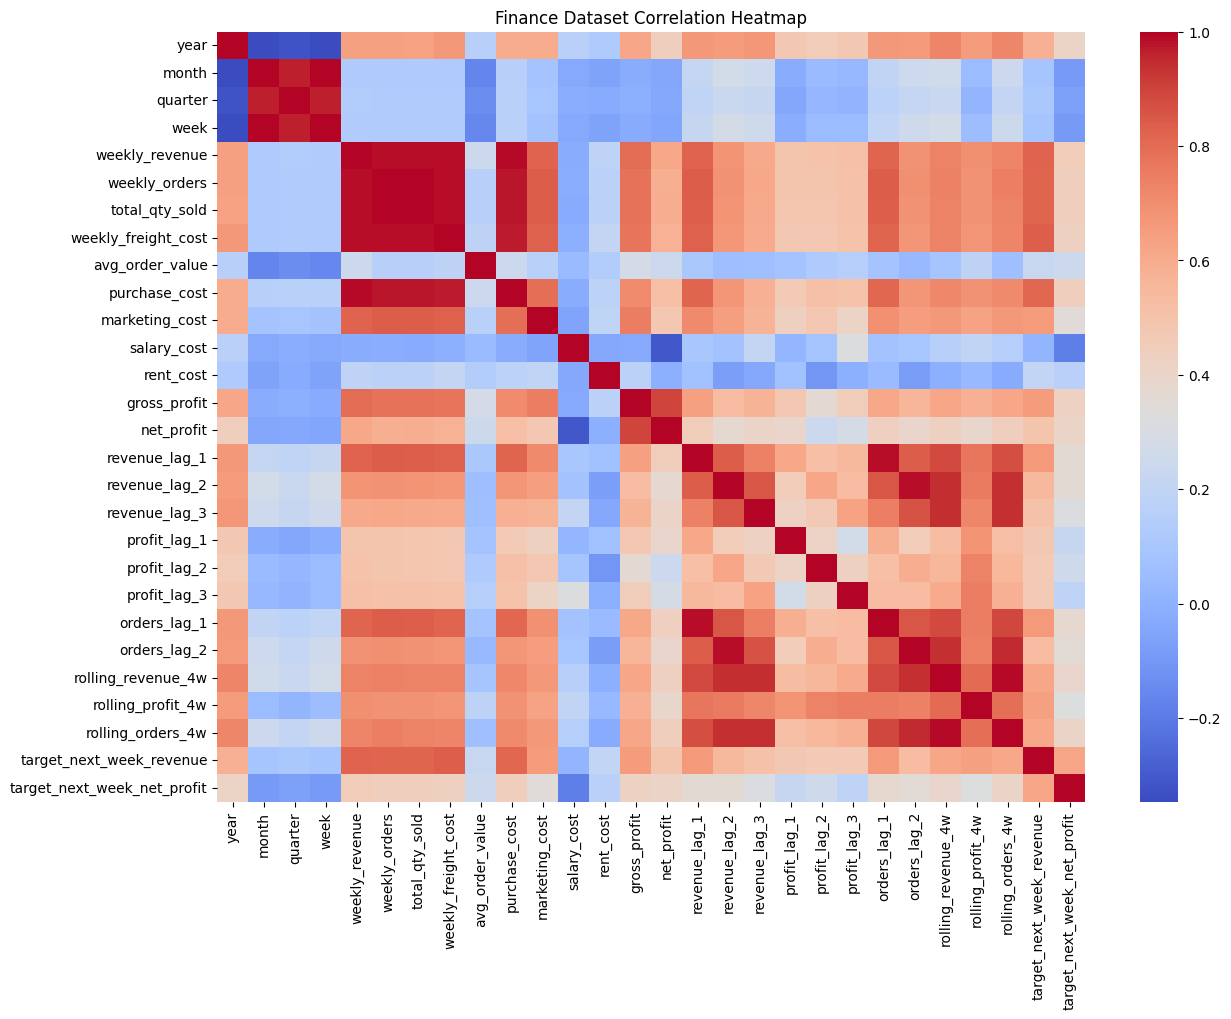

In [8]:
plt.figure(figsize=(14, 10))
sns.heatmap(finance_df.corr(numeric_only=True), cmap="coolwarm", annot=False)
plt.title("Finance Dataset Correlation Heatmap")
plt.show()

## Target Columns

In [9]:
target_columns = [
    "target_next_week_revenue",
    "target_next_week_net_profit"
]

target_columns

['target_next_week_revenue', 'target_next_week_net_profit']

## Feature Columns

In [10]:
feature_columns = [
    col for col in finance_df.columns
    if col not in target_columns
]

feature_columns

['year',
 'month',
 'quarter',
 'week',
 'weekly_revenue',
 'weekly_orders',
 'total_qty_sold',
 'weekly_freight_cost',
 'avg_order_value',
 'purchase_cost',
 'marketing_cost',
 'salary_cost',
 'rent_cost',
 'gross_profit',
 'net_profit',
 'revenue_lag_1',
 'revenue_lag_2',
 'revenue_lag_3',
 'profit_lag_1',
 'profit_lag_2',
 'profit_lag_3',
 'orders_lag_1',
 'orders_lag_2',
 'rolling_revenue_4w',
 'rolling_profit_4w',
 'rolling_orders_4w']

## Separate Features and Targets

In [11]:
X = finance_df[feature_columns].copy()

y_revenue = finance_df["target_next_week_revenue"].copy()
y_profit = finance_df["target_next_week_net_profit"].copy()

print("X shape:", X.shape)
print("Revenue target shape:", y_revenue.shape)
print("Profit target shape:", y_profit.shape)

X shape: (88, 26)
Revenue target shape: (88,)
Profit target shape: (88,)


## Convert Columns to Numeric

In [12]:
for col in X.columns:
    X[col] = pd.to_numeric(X[col], errors="coerce")

y_revenue = pd.to_numeric(y_revenue, errors="coerce")
y_profit = pd.to_numeric(y_profit, errors="coerce")

print(X.dtypes)

year                     int64
month                    int64
quarter                  int64
week                     int64
weekly_revenue         float64
weekly_orders            int64
total_qty_sold         float64
weekly_freight_cost    float64
avg_order_value        float64
purchase_cost          float64
marketing_cost         float64
salary_cost            float64
rent_cost              float64
gross_profit           float64
net_profit             float64
revenue_lag_1          float64
revenue_lag_2          float64
revenue_lag_3          float64
profit_lag_1           float64
profit_lag_2           float64
profit_lag_3           float64
orders_lag_1           float64
orders_lag_2           float64
rolling_revenue_4w     float64
rolling_profit_4w      float64
rolling_orders_4w      float64
dtype: object


## Handle Missing Target Values

In [13]:
valid_rows = y_revenue.notna() & y_profit.notna()

X = X.loc[valid_rows].reset_index(drop=True)
y_revenue = y_revenue.loc[valid_rows].reset_index(drop=True)
y_profit = y_profit.loc[valid_rows].reset_index(drop=True)

print("Final dataset size:", len(X))

Final dataset size: 88


## Train-Test Split

In [14]:
# Keep the same row order for a time-based finance dataset.
split_index = int(len(X) * 0.80)

X_train = X.iloc[:split_index].copy()
X_test = X.iloc[split_index:].copy()

y_revenue_train = y_revenue.iloc[:split_index].copy()
y_revenue_test = y_revenue.iloc[split_index:].copy()

y_profit_train = y_profit.iloc[:split_index].copy()
y_profit_test = y_profit.iloc[split_index:].copy()

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 70
Testing rows: 18


## Preprocessing

In [15]:
preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

## Linear Regression Model

In [16]:
linear_revenue_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

linear_profit_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

In [17]:
linear_revenue_model.fit(X_train, y_revenue_train)
linear_profit_model.fit(X_train, y_profit_train)

print("Linear Regression models trained successfully.")

Linear Regression models trained successfully.


## Random Forest Regression Model

In [18]:
rf_revenue_model = Pipeline([
    ("preprocessor", SimpleImputer(strategy="median")),
    ("regressor", RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        min_samples_leaf=2
    ))
])

rf_profit_model = Pipeline([
    ("preprocessor", SimpleImputer(strategy="median")),
    ("regressor", RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        min_samples_leaf=2
    ))
])

In [19]:
rf_revenue_model.fit(X_train, y_revenue_train)
rf_profit_model.fit(X_train, y_profit_train)

print("Random Forest models trained successfully.")

Random Forest models trained successfully.


## Gradient Boosting Regression Model

In [20]:
gb_revenue_model = Pipeline([
    ("preprocessor", SimpleImputer(strategy="median")),
    ("regressor", GradientBoostingRegressor(random_state=42))
])

gb_profit_model = Pipeline([
    ("preprocessor", SimpleImputer(strategy="median")),
    ("regressor", GradientBoostingRegressor(random_state=42))
])

In [21]:
gb_revenue_model.fit(X_train, y_revenue_train)
gb_profit_model.fit(X_train, y_profit_train)

print("Gradient Boosting models trained successfully.")

Gradient Boosting models trained successfully.


## Revenue Predictions

In [22]:
revenue_predictions = {
    "Linear Regression": linear_revenue_model.predict(X_test),
    "Random Forest": rf_revenue_model.predict(X_test),
    "Gradient Boosting": gb_revenue_model.predict(X_test)
}

for name, pred in revenue_predictions.items():
    print(name, ":", pred[:5])

Linear Regression : [251000.11346119 270746.22544612 261085.53917878 210124.3213754
 236170.98691701]
Random Forest : [218253.47733347 217371.12112185 230553.94170173 140581.40733839
 160366.81440542]
Gradient Boosting : [214017.97514436 204766.39233125 224260.12287898 127411.88395461
 146476.10927807]


## Net Profit Predictions

In [23]:
profit_predictions = {
    "Linear Regression": linear_profit_model.predict(X_test),
    "Random Forest": rf_profit_model.predict(X_test),
    "Gradient Boosting": gb_profit_model.predict(X_test)
}

for name, pred in profit_predictions.items():
    print(name, ":", pred[:5])

Linear Regression : [ 4069.41502826 -3230.83543512  1119.39851374  7520.9856942
   698.7017893 ]
Random Forest : [ -8072.19513076 -10789.86352149  -9952.68757587 -12674.87756762
 -10707.54362106]
Gradient Boosting : [ -9993.62721724 -20280.49049286 -14869.92346623 -14015.63215702
 -14083.85140376]


## Evaluation Function

In [24]:
def evaluate_regression(y_true, y_pred, model_name, target_name):
    mse = mean_squared_error(y_true, y_pred)

    return {
        "Target": target_name,
        "Model": model_name,
        "MAE": mean_absolute_error(y_true, y_pred),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "R2": r2_score(y_true, y_pred)
    }

## Revenue Model Evaluation

In [25]:
revenue_results = []

for name, pred in revenue_predictions.items():
    revenue_results.append(
        evaluate_regression(
            y_revenue_test,
            pred,
            name,
            "Next Week Revenue"
        )
    )

revenue_results_df = pd.DataFrame(revenue_results)
revenue_results_df

,Target,Model,MAE,MSE,RMSE,R2
0,Next Week Revenue,Linear Regression,118406.262450,1.927722e+10,138842.437087,-2.012769
1,Next Week Revenue,Random Forest,57901.306238,4.417207e+09,66462.073176,0.309650
2,Next Week Revenue,Gradient Boosting,60683.184198,4.816309e+09,69399.634759,0.247276


## Net Profit Model Evaluation

In [26]:
profit_results = []

for name, pred in profit_predictions.items():
    profit_results.append(
        evaluate_regression(
            y_profit_test,
            pred,
            name,
            "Next Week Net Profit"
        )
    )

profit_results_df = pd.DataFrame(profit_results)
profit_results_df

,Target,Model,MAE,MSE,RMSE,R2
0,Next Week Net Profit,Linear Regression,15427.654995,3.845948e+08,19611.088279,-5.436537
1,Next Week Net Profit,Random Forest,7859.692214,8.122744e+07,9012.626813,-0.359414
2,Next Week Net Profit,Gradient Boosting,10419.551362,1.295671e+08,11382.755358,-1.168421


## Combined Model Evaluation

In [27]:
model_evaluation = pd.concat(
    [revenue_results_df, profit_results_df],
    ignore_index=True
)

model_evaluation

,Target,Model,MAE,MSE,RMSE,R2
0,Next Week Revenue,Linear Regression,118406.262450,1.927722e+10,138842.437087,-2.012769
1,Next Week Revenue,Random Forest,57901.306238,4.417207e+09,66462.073176,0.309650
2,Next Week Revenue,Gradient Boosting,60683.184198,4.816309e+09,69399.634759,0.247276
3,Next Week Net Profit,Linear Regression,15427.654995,3.845948e+08,19611.088279,-5.436537
4,Next Week Net Profit,Random Forest,7859.692214,8.122744e+07,9012.626813,-0.359414
5,Next Week Net Profit,Gradient Boosting,10419.551362,1.295671e+08,11382.755358,-1.168421


## Actual vs Predicted Revenue

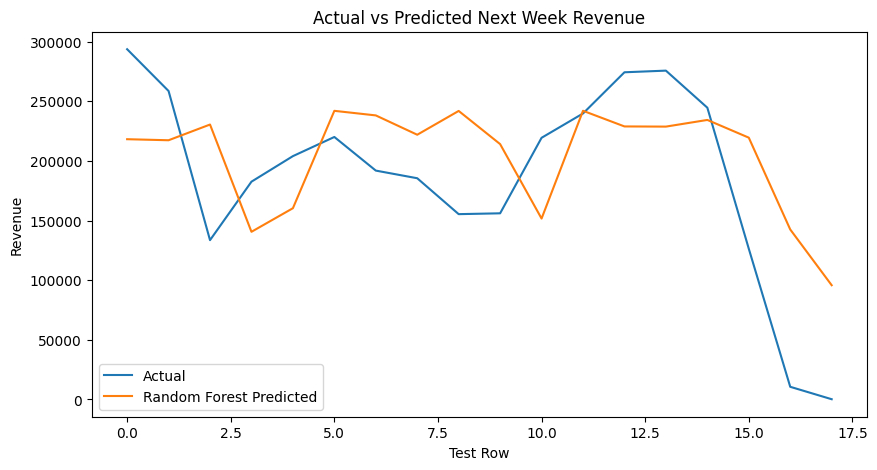

In [28]:
plt.figure(figsize=(10, 5))
plt.plot(y_revenue_test.to_numpy(), label="Actual")
plt.plot(
    revenue_predictions["Random Forest"],
    label="Random Forest Predicted"
)
plt.title("Actual vs Predicted Next Week Revenue")
plt.xlabel("Test Row")
plt.ylabel("Revenue")
plt.legend()
plt.show()

## Actual vs Predicted Net Profit

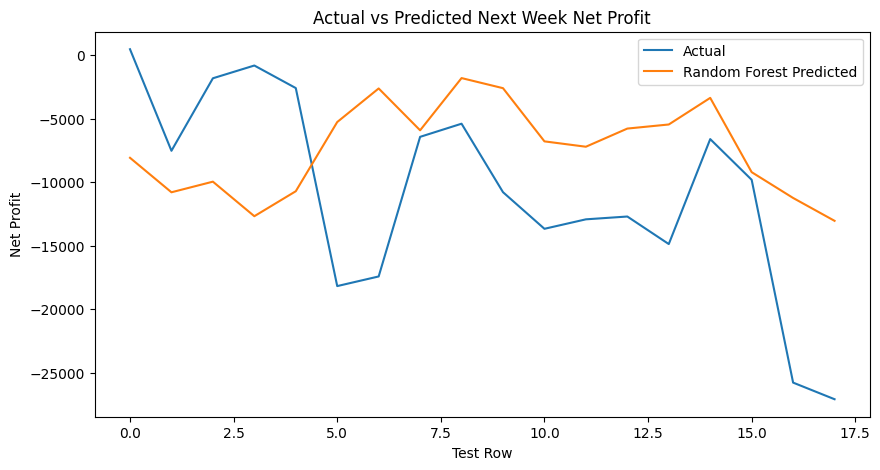

In [29]:
plt.figure(figsize=(10, 5))
plt.plot(y_profit_test.to_numpy(), label="Actual")
plt.plot(
    profit_predictions["Random Forest"],
    label="Random Forest Predicted"
)
plt.title("Actual vs Predicted Next Week Net Profit")
plt.xlabel("Test Row")
plt.ylabel("Net Profit")
plt.legend()
plt.show()

## Select Random Forest for Finance Agent

In [30]:
# Random Forest is used as the deployed model in finance_agent.py.
# The evaluation table above is retained so the models can be compared.

final_revenue_model = rf_revenue_model
final_profit_model = rf_profit_model

print("Final Finance Agent models selected.")

Final Finance Agent models selected.


## Save Finance Models

In [31]:
model_dir = "models"
os.makedirs(model_dir, exist_ok=True)

joblib.dump(
    final_revenue_model,
    os.path.join(model_dir, "target_next_week_revenue_model.pkl")
)

joblib.dump(
    final_profit_model,
    os.path.join(model_dir, "target_next_week_net_profit_model.pkl")
)

joblib.dump(
    feature_columns,
    os.path.join(model_dir, "finance_features.pkl")
)

model_evaluation.to_csv(
    os.path.join(model_dir, "model_evaluation.csv"),
    index=False
)

print("Saved:")
print("1. target_next_week_revenue_model.pkl")
print("2. target_next_week_net_profit_model.pkl")
print("3. finance_features.pkl")
print("4. model_evaluation.csv")

Saved:
1. target_next_week_revenue_model.pkl
2. target_next_week_net_profit_model.pkl
3. finance_features.pkl
4. model_evaluation.csv


## Test Saved Models

In [32]:
saved_revenue_model = joblib.load(
    os.path.join(model_dir, "target_next_week_revenue_model.pkl")
)

saved_profit_model = joblib.load(
    os.path.join(model_dir, "target_next_week_net_profit_model.pkl")
)

sample = X_test.iloc[[0]]

print(
    "Predicted next week revenue:",
    saved_revenue_model.predict(sample)[0]
)

print(
    "Predicted next week net profit:",
    saved_profit_model.predict(sample)[0]
)

Predicted next week revenue: 218253.47733347223
Predicted next week net profit: -8072.195130764079


## Finance AI Training Completed

The trained models and feature list are now ready to be used by `finance_agent.py`.